<div style="background:linear-gradient(90deg,#e8f5e9,#e3f2fd);border:1px solid #90caf9;border-radius:8px;padding:1em 1.4em;margin:0 0 1.2em 0;font-size:1.02em;">
  <strong>🌐 Open Educational Resource</strong><br>
  Except where otherwise noted, this work »Matplotlib & Seaborn« by Martin Uray is licensed under <a href="https://creativecommons.org/licenses/by-sa/4.0/" target="_blank" rel="license noopener">CC BY-SA 4.0</a>.<br>
  <a href="https://creativecommons.org/licenses/by-sa/4.0/" target="_blank" rel="license noopener">
    <img alt="Creative Commons License" style="border-width:0;margin-top:6px;" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png"/>
  </a>
</div>

# matplotlib, seaborn

In [ ]:
!pip install matplotlib==3.11.1
!pip install seaborn==0.13.2
!pip install plotly==6.9.0
!pip install scikit-learn==1.9.0

## Comparison
**matplotlib** is the standard Python plotting library. **seaborn** is based on matplotlib and provides a more high-level interface, different styles, and interfaces nicely with pandas dataframes.

Take a look at how the two libraries render a standard histogram:

In [1]:
import numpy as np
x = np.random.randn(100)
x[:10]

array([-0.15500673, -0.04880281,  0.5640284 ,  1.54007864, -0.77029224,
        0.36312501,  1.08096579,  0.32431566, -0.84267683, -0.74983335])

### Matplotlib
![Matplotlib logo](https://raw.githubusercontent.com/matplotlib/matplotlib/main/doc/_static/logo2.svg)

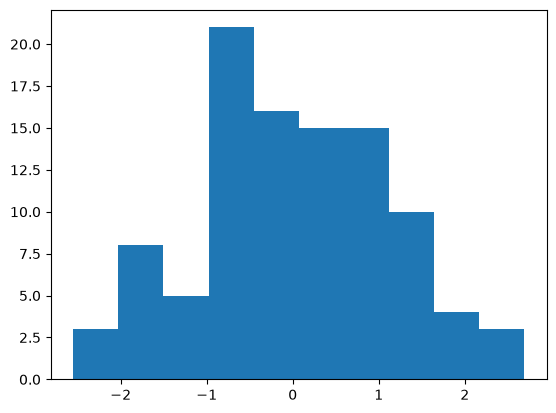

In [2]:
import matplotlib.pyplot as plt
plt.hist(x)
plt.show()

### Seaborn
![Seaborn logo](https://seaborn.pydata.org/_static/logo-wide-lightbg.svg)

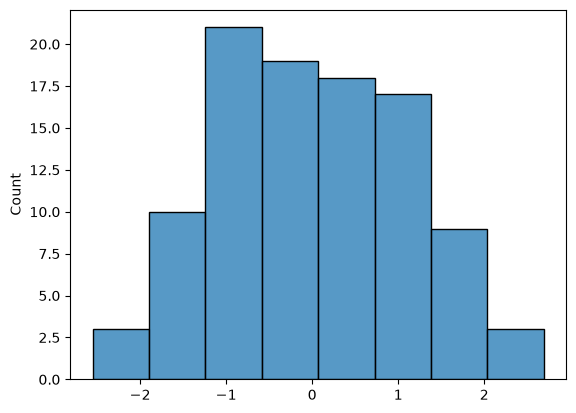

In [3]:
import seaborn as sns
sns.histplot(x)
plt.show()

## Matplotlib, seaborn, pandas?
If confused about how and when to use which framework, the following thoughts can guide you:
1. Use pandas plotting utilities to get a first idea of what your data looks like.
2. Use seaborn for advanced styling and more complex graph types.
3. Use the underlying matplotlib functionality to customize your plot.

## Parts of a Figure
Most of the upcoming terminology might be straightforward. Note the difference between ``Figure`` and ``Axes``. The ``Figure`` is the final image and contains one or more ``Axes``. An ``Axes`` is one actual plot. ``Axis`` means something different and refers to the dimension in the plot and defines the limits, ranges, and ticks.

![Anatomy of a Figure](https://matplotlib.org/_images/anatomy1.png)

Source: https://matplotlib.org/stable/gallery/showcase/anatomy.html

## An Example

### Importing Libraries and Data Loading

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
# use matplotlib in jupyter notebook
%matplotlib inline  
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/ADSLab-Salzburg/DataAnalysiswithPython/main/data/Automobile_data.csv', index_col=0)
df.head()

,company,body-style,wheel-base,length,engine-type,num-of-cylinders,horsepower,average-mileage,price
index,,,,,,,,,
0,alfa-romero,convertible,88.6,168.8,dohc,four,111,21,13495.0
1,alfa-romero,convertible,88.6,168.8,dohc,four,111,21,16500.0
2,alfa-romero,hatchback,94.5,171.2,ohcv,six,154,19,16500.0
3,audi,sedan,99.8,176.6,ohc,four,102,24,13950.0
4,audi,sedan,99.4,176.6,ohc,five,115,18,17450.0


### Data Types
Which of the columns contain qualitative (categorical, ordinal) or quantitative (continuous or discrete) data?

### Seaborn's Plotting Functions
There are two ways to create a plot in seaborn:
1. (recommended) Pass a ``DataFrame`` to the ``data`` argument, while passing column names to the axes arguments, ``x`` and ``y``.
2. Directly pass in ``Series`` of data to the axes arguments.


### Scatter Plot
Seaborn provides a [``scatterplot()``](http://seaborn.pydata.org/generated/seaborn.scatterplot.html#seaborn.scatterplot) function.

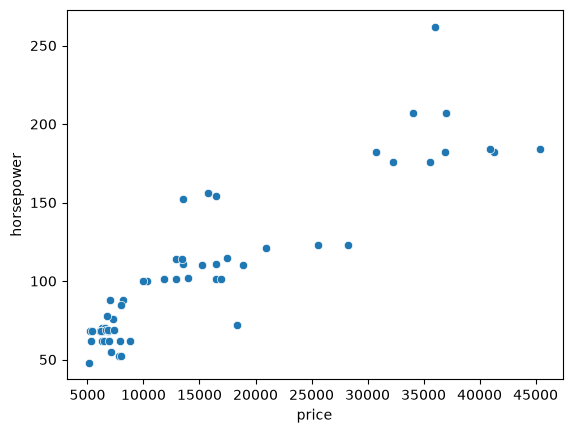

In [5]:
sns.scatterplot(x='price', y='horsepower', data=df)
plt.show()

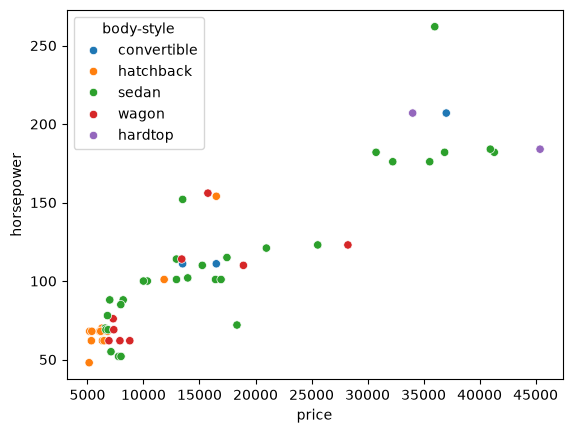

In [6]:
sns.scatterplot(x='price', y='horsepower', data=df,
                hue='body-style')  # color by body style
plt.show()

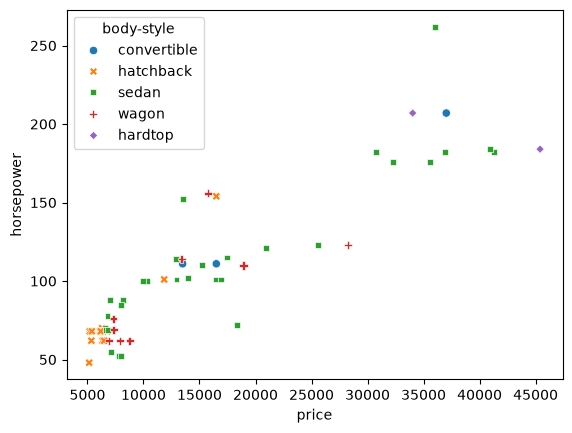

In [7]:
sns.scatterplot(x='price', y='horsepower', data=df,
                hue='body-style',
                style='body-style')  # change marker style according to body style
plt.show()

### Customization with Matplotlib
seaborn is a high-level interface to matplotlib. Some low-level functionality is still handled in matplotlib only:

#### Setting axis limits

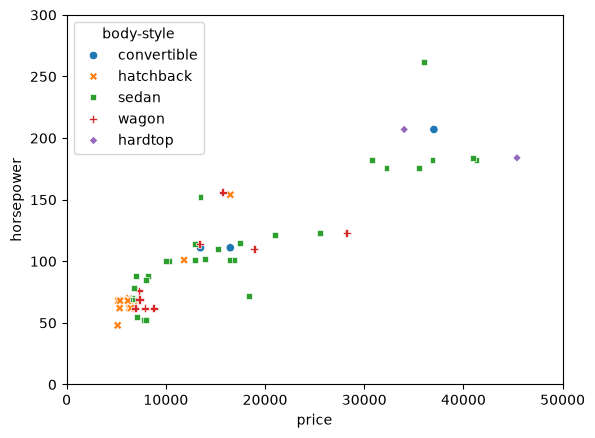

In [8]:
sns.scatterplot(x='price', y='horsepower', data=df,
                hue='body-style', style='body-style')
plt.xlim(0, 50000)
plt.ylim(0, 300)
plt.show()

#### Defining a title

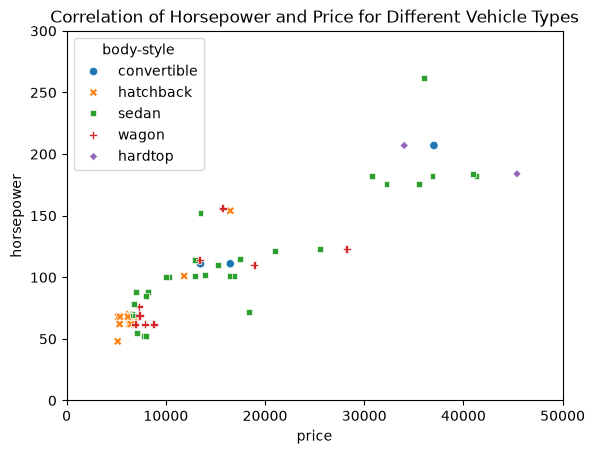

In [9]:
sns.scatterplot(x='price', y='horsepower', data=df,
                hue='body-style', style='body-style')
plt.xlim(0, 50000)
plt.ylim(0, 300)

plt.title('Correlation of Horsepower and Price for Different Vehicle Types')

plt.show()

#### Legend position

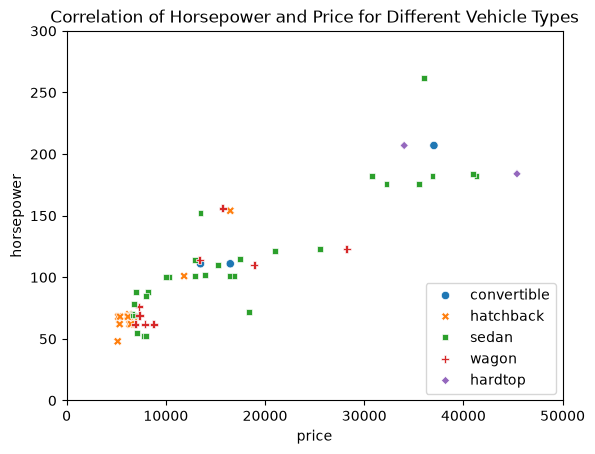

In [10]:
sns.scatterplot(x='price', y='horsepower', data=df,
                hue='body-style', style='body-style')
plt.xlim(0, 50000)
plt.ylim(0, 300)
plt.title('Correlation of Horsepower and Price for Different Vehicle Types')

plt.legend(loc='lower right')  # vs. 'best'

plt.show()

#### x-tick-label rotation

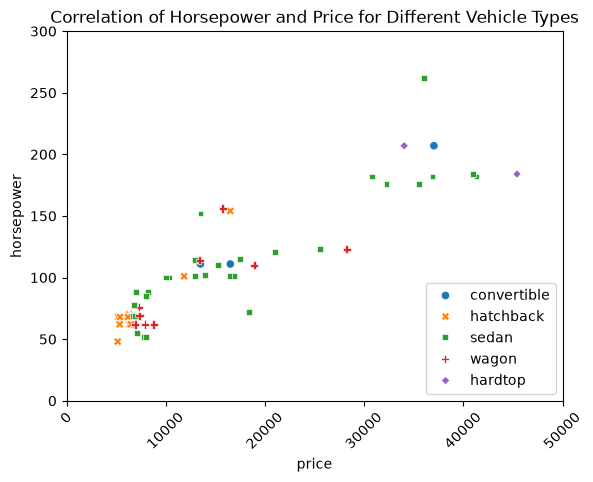

In [11]:
sns.scatterplot(x='price', y='horsepower', data=df,
                hue='body-style', style='body-style')
plt.xlim(0, 50000)
plt.ylim(0, 300)
plt.title('Correlation of Horsepower and Price for Different Vehicle Types')
plt.legend(loc='lower right')

plt.xticks(rotation=45)  # rotate x-tick-labels by 45 degrees

plt.show()

### Seaborn themes
Another advantage of seaborn is that it comes with decent style themes right out of the box. The default theme is called 'darkgrid'. We'll now use 'whitegrid' instead to plot the distribution of selected car companies' prices.

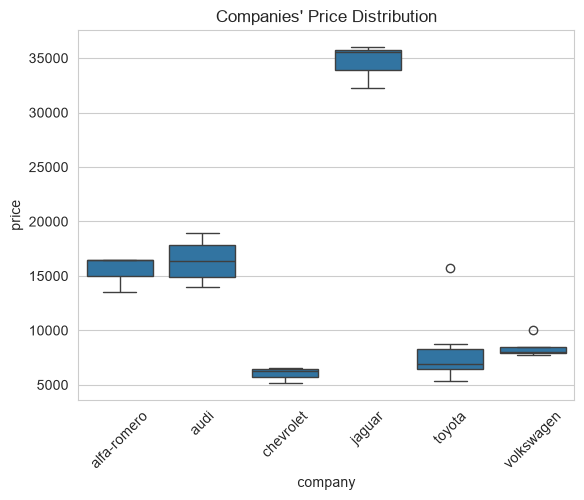

In [12]:
# Choose data
df_company = df.loc[df['company'].str.contains("volkswagen|audi|jaguar|chevrolet|toyota|alfa-romero"), :]

# Set theme
sns.set_style('whitegrid')

# Boxplot
sns.boxplot(x='company', y='price', data=df_company)
plt.xticks(rotation=45)
plt.title('Companies\' Price Distribution')
plt.show()

### Seaborn color palettes
Different countries (and their car manufacturers) are historically aligned with typical colors. We can define color palettes on our own by creating an ordered list of hex values (the same order as the x-axis). We also change the plot type to ``violin`` as this type also displays the data distribution instead of only the summary statistics:


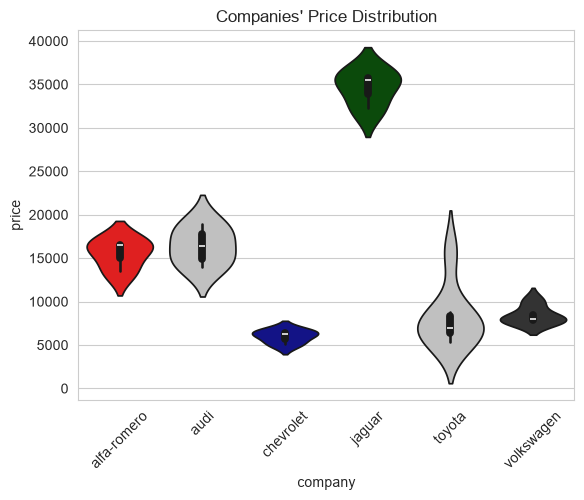

In [13]:
# Define color palette
car_colors = ['#FF0000',  # red for Italian cars
              '#C0C0C0',  # silver for German cars
              '#000099',  # imperial blue for American cars
              '#005500',  # green for British cars
              '#C0C0C0',
              '#333333']  # black for Japanese cars (not too black as we still want to see some information)

# Violin plot
sns.violinplot(x='company', y='price', hue='company', data=df_company, palette=car_colors, density_norm='count')
plt.xticks(rotation=45)
plt.title('Companies\' Price Distribution')
plt.show()

As we can't see too much here, we change the plot type once again to ``swarmplot`` to see the individual data points:

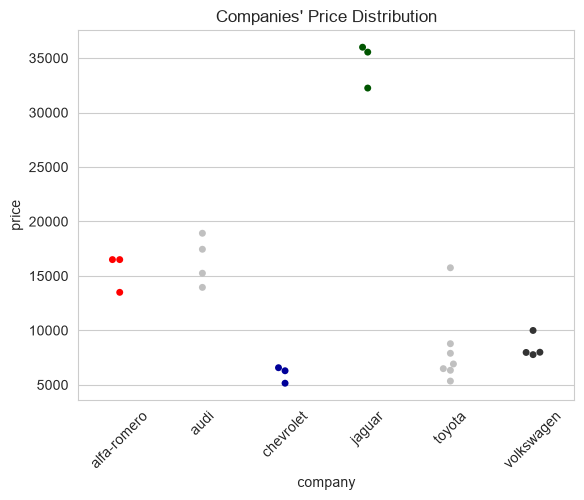

In [14]:
# Swarm plot
sns.swarmplot(x='company', y='price', data=df_company, hue='company', palette=car_colors)
plt.xticks(rotation=45)
plt.title('Companies\' Price Distribution')
plt.show()

## Aside: The Boxplot
```
     Q1-1.5IQR   Q1   median  Q3   Q3+1.5IQR
                  |-----:-----|
  o      |--------|     :     |--------|    o  o
                  |-----:-----|
flier             <----------->            fliers
                       IQR
```

    The box extends from the first quartile (Q1) to the third quartile (Q3) of the data, with a line at the median. The whiskers extend from the box by 1.5x the inter-quartile range (IQR). Flier points are those past the end of the whiskers. See https://en.wikipedia.org/wiki/Box_plot for reference.

Source: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html

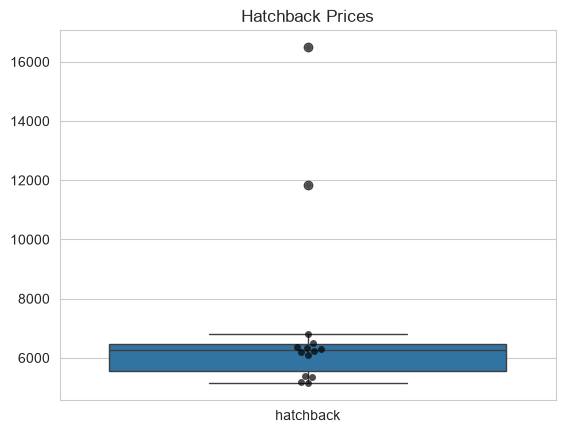

In [15]:
df_hatchback = pd.DataFrame(df.loc[df['body-style'].str.contains('hatchback'), 'price'])
sns.boxplot(data=df_hatchback)
sns.swarmplot(data=df_hatchback, color='k', alpha=.7)
plt.xticks([0], ['hatchback'])
plt.title('Hatchback Prices')
plt.show()

### Combining Plots
We can plot several plots in the same axes to overlay the information. 

In [ ]:
# Optional: Set figure size with matplotlib
plt.figure(figsize=(10,6))
# Violin plot
sns.violinplot(x='company', y='price', hue='company', data=df_company, palette=car_colors, density_norm='count')
# Swarm plot
sns.swarmplot(x='company', y='price', data=df_company, color='w')
plt.xticks(rotation=45)
plt.title('Companies\' Price Distribution')
plt.show()

### Creating Subplots
We can also create several Axes per figure.

In [ ]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8), sharey=True)
sns.violinplot(x='company', y='price', hue='company', data=df_company, palette=car_colors, density_norm='count', ax=ax1)
sns.swarmplot(x='company', y='price', data=df_company, ax=ax2)

ax1.set_title('Companies\' Price Distribution (Violinplot)')
ax2.set_title('Companies\' Price Distribution (Swarmplot)')
ax2.set_ylabel("")
plt.show()

### How to use the plots externally
One does not only want to use the plots internally in notebooks and scripts. Storing the images from the pop-up window can not be automated easily. By using `plt.savefig(...)` (instead of `plt.show()`), we can specify the location to store the file.

__Hint:__ this can be combined with Git and LaTeX in a very cool way!

In [ ]:
plt.figure(figsize=(10,6))
sns.violinplot(x='company', y='price', hue='company',
               data=df_company, palette=car_colors, 
               density_norm='count')

sns.swarmplot(x='company', y='price', data=df_company, color='w')
plt.xticks(rotation=45)
plt.title('Companies\' Price Distribution')

# instead of plt.show()
plt.savefig('sample_figure.png', dpi=150)

But we don't want to keep that file. Let's clean up. ;-)

In [ ]:
import os; os.remove('sample_figure.png')

## Do you know XKCD?
![XKCD](https://imgs.xkcd.com/comics/python_environment.png)

If you want to make a graph like that, google for `matplotlib` and `xkcd`.

<div style="font-size:0.8em;color:#666;">&copy; Randall Munroe, <a href="https://xkcd.com/1987/" target="_blank" rel="noopener">xkcd.com</a>, licensed <a href="https://xkcd.com/license.html" target="_blank" rel="noopener">CC BY-NC 2.5</a> &mdash; not covered by this notebook's CC BY-SA 4.0 license.</div>

## One step further: Plotly

    The plotly Python library is an interactive, open-source plotting library that supports over 40 unique chart types covering a wide range of statistical, financial, geographic, scientific, and 3-dimensional use-cases.

    Built on top of the Plotly JavaScript library (plotly.js), plotly enables Python users to create beautiful interactive web-based visualizations that can be displayed in Jupyter notebooks, saved to standalone HTML files, or served as part of pure Python-built web applications using Dash. The plotly Python library is sometimes referred to as "plotly.py" to differentiate it from the JavaScript library.
    
Source: [https://plotly.com/python/getting-started/](https://plotly.com/python/getting-started/)

Let's have a look at a basic example...

In [ ]:
import plotly.express as px
fig = px.bar(x=["a", "b", "c"], y=[1, 3, 2])
fig.show()

But there is much more...

In [ ]:
import plotly.express as px
df = px.data.gapminder()
df.head()

In [ ]:
fig = px.bar(df.query('year == 2007'), 
             hover_name='country',
             y='continent',
             barmode="group"
            )
fig.show()

In [ ]:
px.scatter(df, x="gdpPercap", y="lifeExp", animation_frame="year", animation_group="country",
           size="pop", color="continent", hover_name="country",
           log_x=True, size_max=55, range_x=[100,100000], range_y=[25,90])

In [ ]:
fig = px.scatter_geo(
    df.query('year == 2007'), 
    locations='iso_alpha', 
    color='continent', 
    projection='orthographic',
    hover_name="country"
)
fig.show() 

In [ ]:
import plotly.graph_objects as go

import pandas as pd

# Read data from a csv
z_data = pd.read_csv('https://raw.githubusercontent.com/plotly/datasets/master/api_docs/mt_bruno_elevation.csv')

fig = go.Figure(data=[go.Surface(z=z_data.values)])

fig.update_layout(title='Mt Bruno Elevation', autosize=False,
                  width=500, height=500,
                  margin=dict(l=65, r=50, b=65, t=90))

fig.show()

## Wrap-up Exercises

### Task 1: Automobile Data
Browse the [seaborn API reference](http://seaborn.pydata.org/api.html) or the [example gallery](https://seaborn.pydata.org/examples/index.html) and come up with your visualization of the automobile data. Store it on your disc and upload it to the quiz of reading 2. Two students' graphs should not look the same! I am curious about your visualizations.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### Task 2: Sales Data Analysis with Matplotlib

Use seaborn and matplotlib to analyze and visualize a dataset of monthly sales for different product categories. Create a line plot with customizations to enhance readability, and use annotations to highlight specific points of interest.

1. Dataset Preparation:
- Create a dataset with the following columns: Month, Category, and Sales. Include data for 12 months and 3 categories (Electronics, Furniture, Clothing).
- Generate random sales values between 5000 and 20000 for each category.

2. Line Plot:
- Use seaborn/matplotlib to create a line plot showing sales trends over the 12 months for each category.
- Each category should have a different line color and line style.

3. Customization:
- Add a title, axis labels, and a legend.
- Highlight the month with the highest total sales (across all categories) by marking it with a red dot and adding an annotation to show the total sales value for that month.
- Add grid lines and adjust the plot style (e.g., using plt.style.use('seaborn-darkgrid')).

4. Enhance Plot with Annotations:
Annotate each category's highest sales month with the specific sales value.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### Task 3: Exploring Iris Dataset with Matplotlib and Seaborn

In this task, you'll work with a classic dataset in machine learning: the Iris dataset. You'll use Matplotlib and Seaborn to visualize 
the data and gain insights into the characteristics of each species.

**Objective:**

* Load the Iris dataset
* Create **ONE** figure with several subplots:
    * Create a histogram of the sepal length
    * Create a boxplot of the petal width
    * Compare the distributions of sepal length and petal width across species using violin plots
    * Use Seaborn's heatmap to visualize the relationship between sepal length, sepal width, petal length, and petal width

**Dataset:**

The Iris dataset is a multiclass classification problem, where we have three classes (Iris setosa, Iris versicolor, and Iris 
virginica) with 50 instances each. The dataset consists of four features:

* sepal length (cm)
* sepal width (cm)
* petal length (cm)
* petal width (cm)

**Tips and Resources:**

* Use the [`iris` dataset from Scikit-Learn library](https://scikit-learn.org/1.5/modules/generated/sklearn.datasets.load_iris.html)

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### Task 4: Visualizing COVID-19 Cases by Country using Plotly

In this task, you'll create an interactive visualization of COVID-19 cases by country using Plotly. You'll use publicly available data from the Our World in Data project.

**Objective:**

* Load and clean the COVID-19 dataset
* Create a plot of total cases by country

In [ ]:
import plotly.express as px
import pandas as pd

# Load dataset from CSV file or URL
url = 'https://raw.githubusercontent.com/owid/covid-19-data/refs/heads/master/public/data/owid-covid-data.csv'
df = pd.read_csv(url)

# YOUR CODE HERE
raise NotImplementedError()

<div style="background:linear-gradient(90deg,#e3f2fd,#e8f5e9);border:1px solid #90caf9;border-radius:8px;padding:1em 1.4em;margin:1.4em 0 0 0;">
  <strong>📚 Inspiration / Further Reading</strong>
  <ul style="margin:0.5em 0 0 0;">
    <li><a href="https://blog.magrathealabs.com/choosing-one-of-many-python-visualization-tools-7eb36fa5855f" target="_blank" rel="noopener">Blog post about Python visualization tools</a></li>
    <li><a href="https://matplotlib.org/faq/usage_faq.html" target="_blank" rel="noopener">matplotlib usage FAQ</a></li>
    <li><a href="https://erikcianci.com/blog/data-visualization-fundamentals#data-types" target="_blank" rel="noopener">Data visualization blog post</a></li>
    <li><a href="https://elitedatascience.com/python-seaborn-tutorial" target="_blank" rel="noopener">Python seaborn tutorial</a></li>
  </ul>
</div>